# Comparing RGB and Wavelet Representations for CNN-Based Deepfake Face Detection

Three DenseNet-121 models are trained from scratch on the same data with different inputs:

| Model | Input | Channels |
|---|---|---|
| RGB Only | RGB image scaled to [0, 1] | 3 |
| Wavelets Only | Haar DWT high-frequency sub-bands (LH, HL, HH) of each colour channel | 9 |
| RGB + Wavelets | Both stacked | 12 |

The notebook covers data exploration, preprocessing, training, evaluation on the held-out test set
(metrics, ROC, confusion matrices, McNemar's test) and Grad-CAM attention maps.

Outputs are from the original run on Google Colab (NVIDIA L4 GPU). Set `TRAIN = True` to retrain;
otherwise the saved weights in `WEIGHTS_DIR` are loaded.

In [ ]:
import os
import random
import time

import cv2
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pywt
import seaborn as sns
import tensorflow as tf
from PIL import Image
from sklearn import metrics
from sklearn.model_selection import StratifiedKFold
from statsmodels.stats.contingency_tables import mcnemar
from tensorflow import keras
from tensorflow.keras import callbacks
from tqdm import tqdm

import warnings
warnings.filterwarnings("ignore")

In [ ]:
# Dataset: "140k Real and Fake Faces" on Kaggle (real faces from FFHQ, fake faces from StyleGAN)
path = kagglehub.dataset_download("xhlulu/140k-real-and-fake-faces")
dataset_dir = os.path.join(path, "real_vs_fake", "real-vs-fake")
print("Data directory:", dataset_dir)

WEIGHTS_DIR = "weights"      # where the trained weights are saved / loaded
TRAIN = False                # True: train the three models; False: load saved weights
EXAMPLE_IMAGE = "example_ffhq_1024.png"  # any 1024x1024 FFHQ image, used for one illustration

IMG_SIZE = (256, 256)
BATCH_SIZE = 128
SEED = 57
INITIAL_LR = 1e-4

tf.random.set_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)
os.makedirs(WEIGHTS_DIR, exist_ok=True)

## 1. Data exploration

In [ ]:
# Build dataframe with file paths and labels
all_files = []
all_labels = []

for split in ["train", "valid", "test"]:
    split_dir = os.path.join(dataset_dir, split)

    for label in ["real", "fake"]:
        class_dir = os.path.join(split_dir, label)

        for fname in os.listdir(class_dir):
            all_files.append(os.path.join(class_dir, fname))
            all_labels.append(label)

df = pd.DataFrame({"filename": all_files, "class": all_labels})

print(df)

                                                 filename class
0       /kaggle/input/140k-real-and-fake-faces/real_vs...  real
1       /kaggle/input/140k-real-and-fake-faces/real_vs...  real
2       /kaggle/input/140k-real-and-fake-faces/real_vs...  real
3       /kaggle/input/140k-real-and-fake-faces/real_vs...  real
4       /kaggle/input/140k-real-and-fake-faces/real_vs...  real
...                                                   ...   ...
139995  /kaggle/input/140k-real-and-fake-faces/real_vs...  fake
139996  /kaggle/input/140k-real-and-fake-faces/real_vs...  fake
139997  /kaggle/input/140k-real-and-fake-faces/real_vs...  fake
139998  /kaggle/input/140k-real-and-fake-faces/real_vs...  fake
139999  /kaggle/input/140k-real-and-fake-faces/real_vs...  fake

[140000 rows x 2 columns]

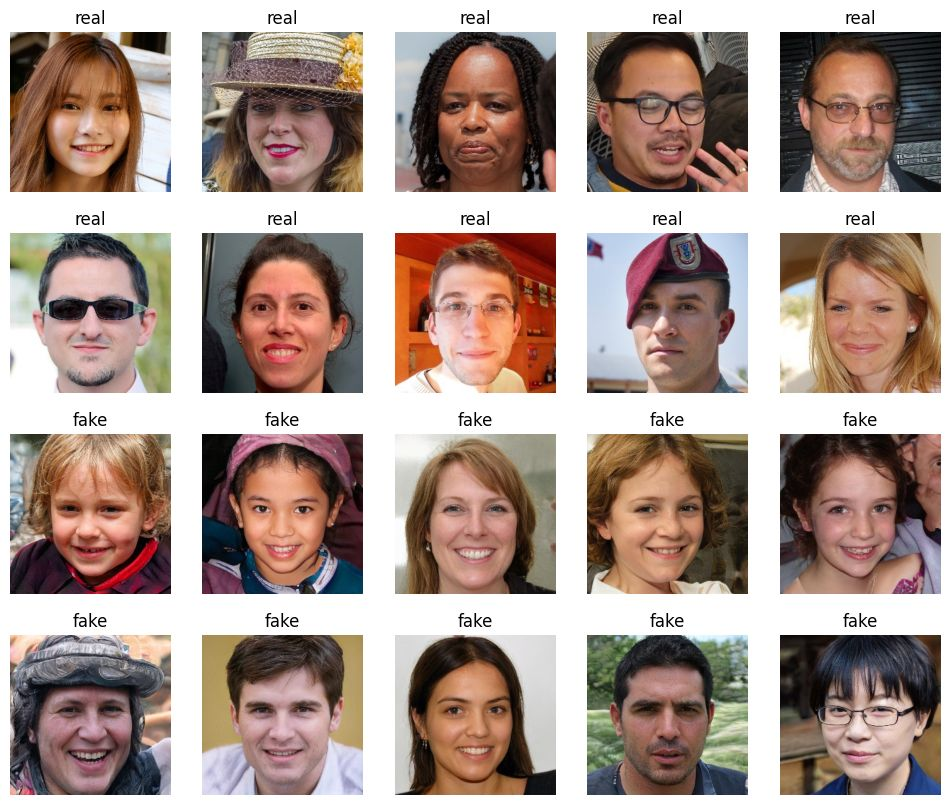

In [ ]:
# Randomly select 10 real and 10 fake images
real_samples = df[df["class"] == "real"].sample(10)
fake_samples = df[df["class"] == "fake"].sample(10)
samples_df = pd.concat([real_samples, fake_samples])

plt.figure(figsize=(12, 10))
for i, row in enumerate(samples_df.itertuples()):
    img = plt.imread(row.filename) / 255.0
    plt.subplot(4, 5, i + 1)
    plt.imshow(img)
    plt.title(row._2)
    plt.axis("off")
plt.show()

### Fourier transform

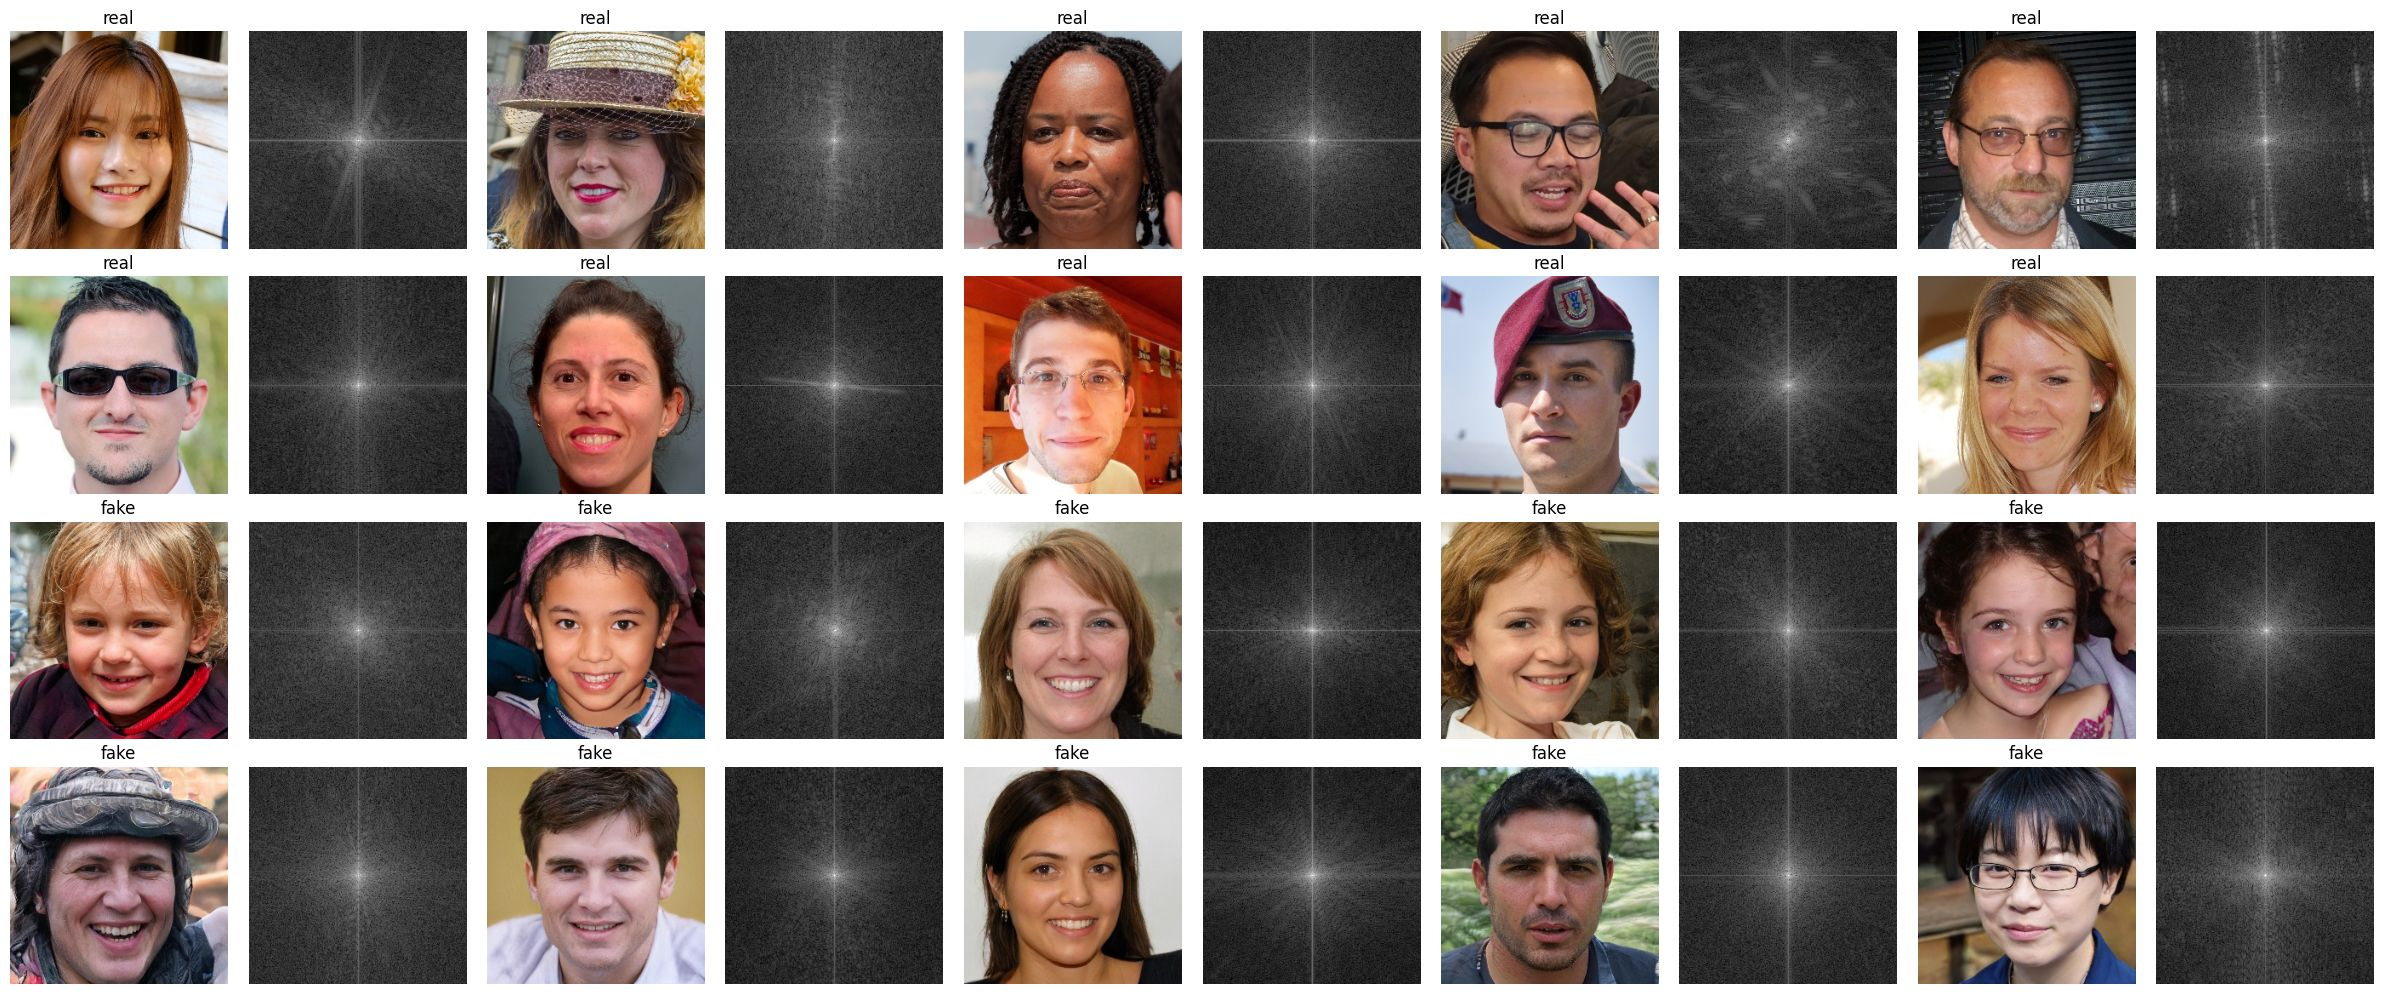

In [ ]:
# Perform fourier transform and display
plt.figure(figsize=(24, 10))
for i, row in enumerate(samples_df.itertuples()):
    img = plt.imread(row.filename) / 255.0  # normalize
    gray = np.mean(img, axis=2) # convert to grayscale
    f = np.fft.fft2(gray)
    fshift = np.fft.fftshift(f)
    magnitude_spectrum = np.log(1 + np.abs(fshift)) # perform fourier transform

    # Left: original image; Right: Fourier magnitude spectrum
    plt.subplot(4, 10, 2*i+1)
    plt.imshow(img)
    plt.title(f"{row._2}")
    plt.axis("off")

    plt.subplot(4, 10, 2*i+2)
    plt.imshow(magnitude_spectrum, cmap='gray')
    plt.axis("off")

plt.tight_layout()
plt.show()

### Haar wavelet transform

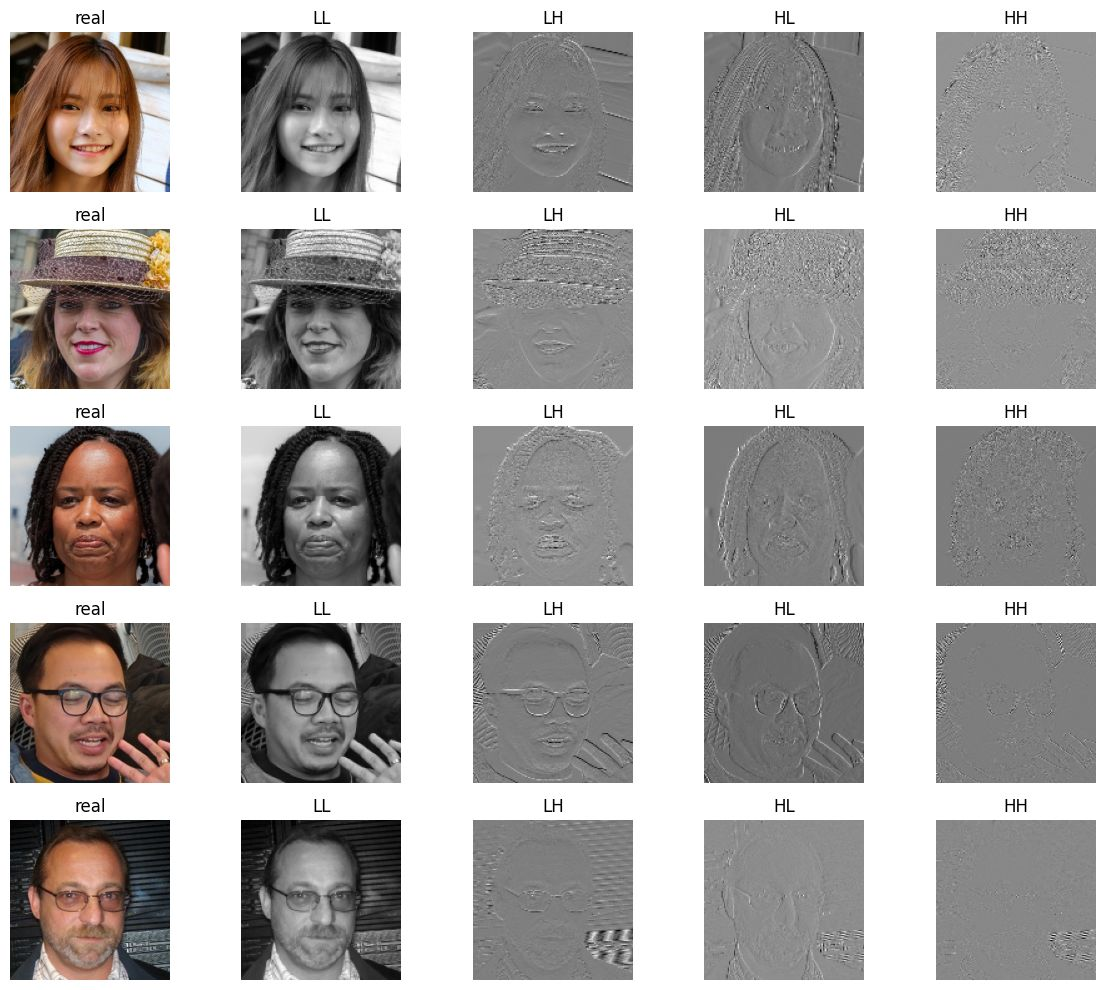

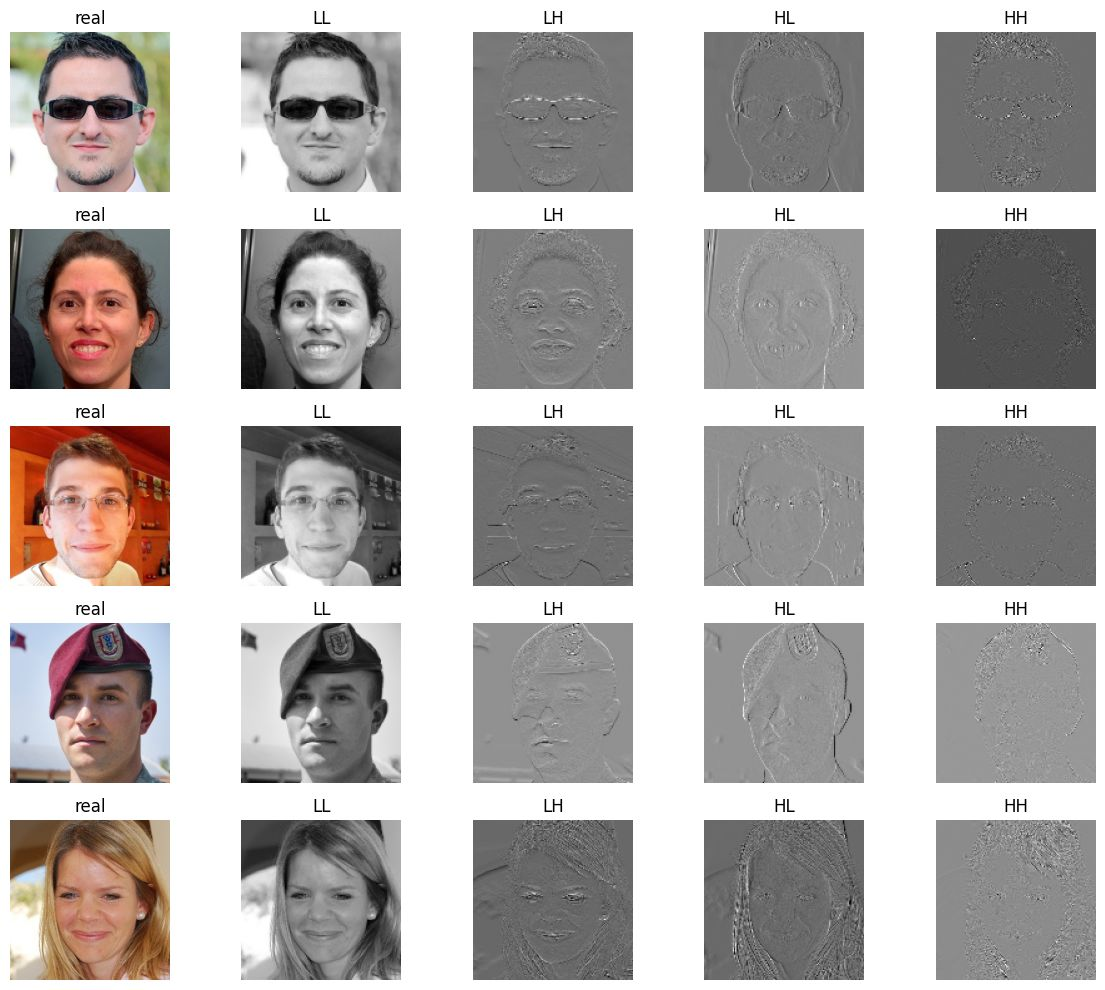

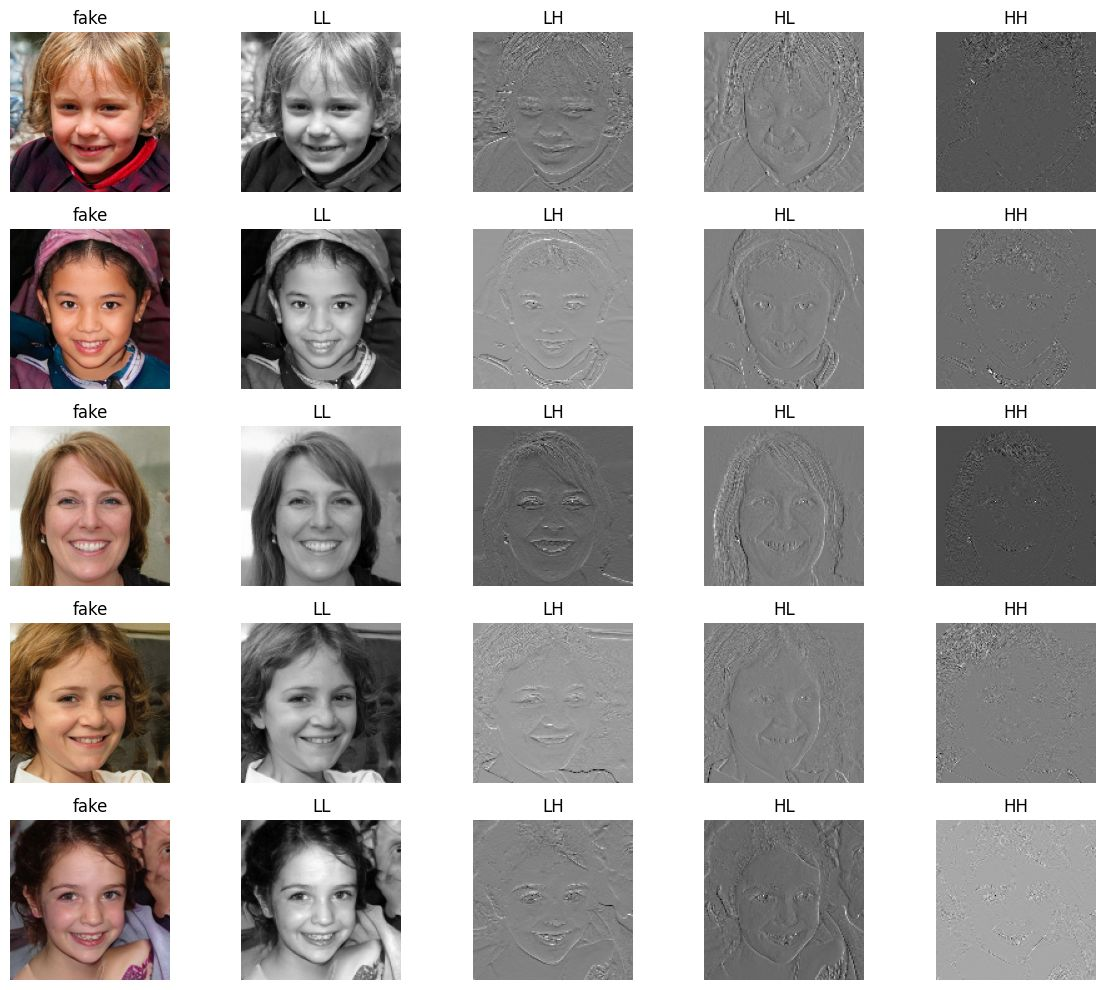

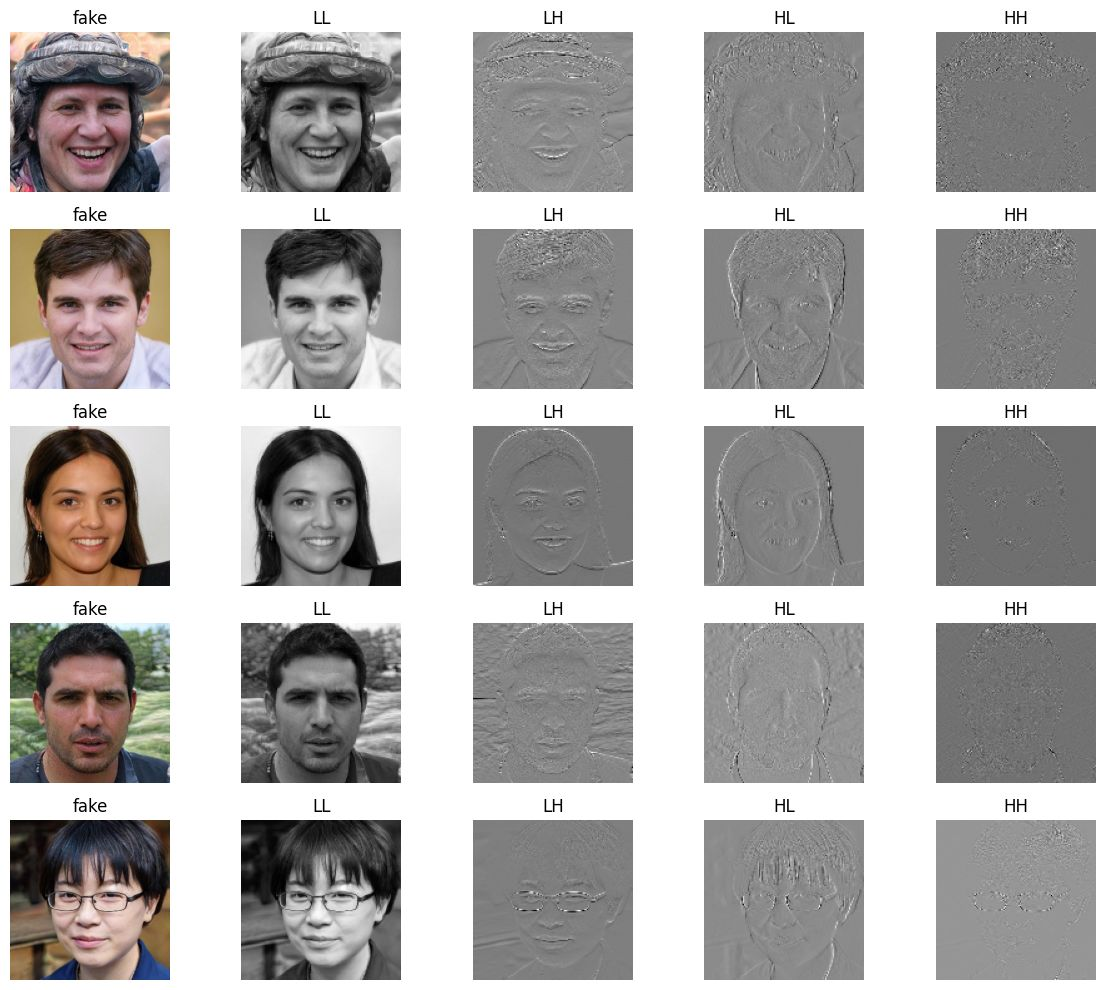

In [ ]:
# Perform wavelet transform and display
plt.figure(figsize=(12,10))
for i, row in enumerate(samples_df.itertuples()):
    # read and normalize
    img = plt.imread(row.filename) / 255.0
    gray = np.mean(img, axis=2)

    # 2D Discrete Wavelet Transform (Haar)
    coeffs2 = pywt.dwt2(gray, 'haar')
    LL, (LH, HL, HH) = coeffs2

    # Show original + 4 sub-bands
    plt.subplot(5, 5, i*5 % 25 + 1); plt.imshow(img); plt.title(f"{row._2}"); plt.axis("off")
    plt.subplot(5, 5, i*5 % 25 + 2); plt.imshow(LL, cmap='gray'); plt.title("LL"); plt.axis("off")
    plt.subplot(5, 5, i*5 % 25 + 3); plt.imshow(LH, cmap='gray'); plt.title("LH"); plt.axis("off")
    plt.subplot(5, 5, i*5 % 25 + 4); plt.imshow(HL, cmap='gray'); plt.title("HL"); plt.axis("off")
    plt.subplot(5, 5, i*5 % 25 + 5); plt.imshow(HH, cmap='gray'); plt.title("HH"); plt.axis("off")

    if (i+1) % 5 == 0:
        plt.tight_layout()
        plt.show()
        plt.figure(figsize=(12,10))

plt.tight_layout()
plt.show()

### A full-resolution example

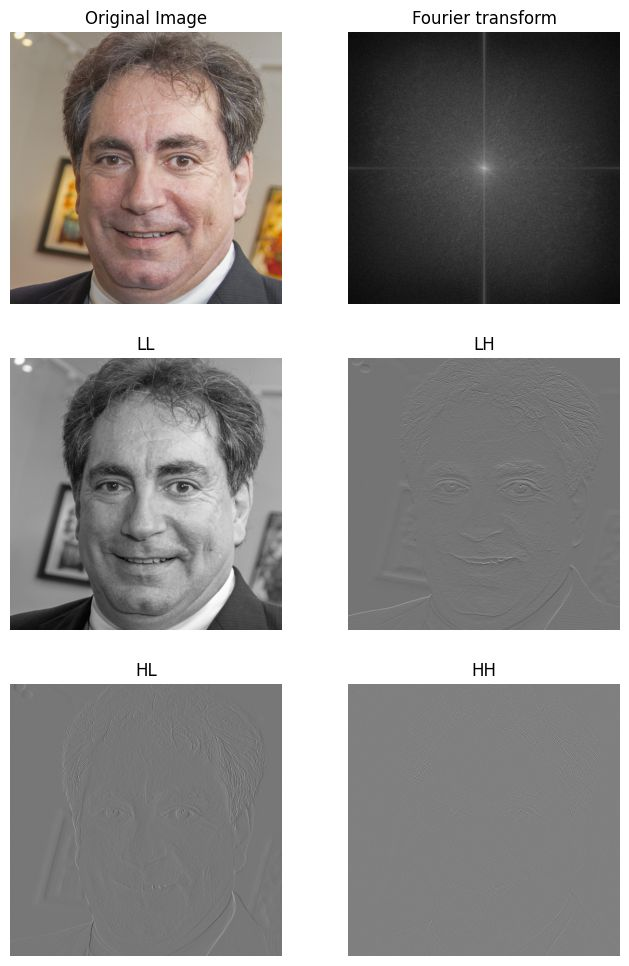

In [ ]:
img = plt.imread(EXAMPLE_IMAGE)
gray = np.mean(img, axis=2)

# Fourier transform
f = np.fft.fft2(gray)
fshift = np.fft.fftshift(f)
magnitude = np.log(1 + np.abs(fshift))

# Wavelet transform
LL, (LH, HL, HH) = pywt.dwt2(gray, "haar")

plt.figure(figsize=(8, 12))
plt.subplot(3, 2, 1); plt.imshow(img); plt.title("Original Image"); plt.axis("off")
plt.subplot(3, 2, 2); plt.imshow(magnitude, cmap="gray"); plt.title("Fourier transform"); plt.axis("off")
plt.subplot(3, 2, 3); plt.imshow(LL, cmap="gray"); plt.title("LL"); plt.axis("off")
plt.subplot(3, 2, 4); plt.imshow(LH, cmap="gray"); plt.title("LH"); plt.axis("off")
plt.subplot(3, 2, 5); plt.imshow(HL, cmap="gray"); plt.title("HL"); plt.axis("off")
plt.subplot(3, 2, 6); plt.imshow(HH, cmap="gray"); plt.title("HH"); plt.axis("off")
plt.show()

### Wavelet normalisation statistics

In [ ]:
# Mean and std of the 9 high-frequency DWT sub-bands (LH, HL, HH for R, G, B),
# estimated on a 10% sample. Only needed once; the values are stored below.
COMPUTE_WAVELET_STATS = False
N_WAVELET_CHANNELS = 9
SAMPLING_FRACTION = 0.1


def compute_wavelet_features_np(np_image):
    """Stacks the 9 high-frequency DWT sub-bands of one RGB image (uint8 array)."""
    wavelet_features = []
    for i in range(3):
        LH, HL, HH = pywt.dwt2(np_image[:, :, i], "haar")[1]
        wavelet_features.extend([LH, HL, HH])
    return np.stack(wavelet_features, axis=-1)


if COMPUTE_WAVELET_STATS:
    df_sample = df.sample(frac=SAMPLING_FRACTION, random_state=42)
    all_wavelet_pixels = []
    for img_path in tqdm(df_sample["filename"]):
        image = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
        all_wavelet_pixels.append(compute_wavelet_features_np(image).reshape(-1, N_WAVELET_CHANNELS))
    combined_data = np.concatenate(all_wavelet_pixels, axis=0)
    print("Wavelet_MEAN =", np.mean(combined_data, axis=0).tolist())
    print("Wavelet_STD  =", np.std(combined_data, axis=0).tolist())

## 2. Datasets and preprocessing

The dataset's own split is used: 100,000 train, 20,000 validation and 20,000 test images.

In [ ]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(dataset_dir, "train"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    seed=SEED
)

valid_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(dataset_dir, "valid"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    seed=SEED
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(dataset_dir, "test"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

Found 100000 files belonging to 2 classes.
Found 20000 files belonging to 2 classes.
Found 20000 files belonging to 2 classes.

In [ ]:
# image_dataset_from_directory sorts class folders alphabetically:
# fake = 0, real = 1, so a prediction > 0.5 means "real".
print("Class names:", train_ds.class_names)

Class names: ['fake', 'real']

In [ ]:
# Values used for training the saved models. They were computed with OpenCV's BGR
# channel order, so channels 0-2 and 6-8 are swapped relative to the RGB pipeline.
# The effect is negligible (means are close to 0 and stds are 7-12 for every channel),
# so the values are kept unchanged to match the trained weights.
Wavelet_MEAN = tf.constant([0.06322062760591507, 0.14566604793071747, 0.004705097526311874, 0.07626466453075409, -0.05939734727144241, 0.005020765122026205, 0.02491244673728943, 0.11974337697029114, 0.004669941496104002], dtype=tf.float32)
Wavelet_STD = tf.constant([11.035733222961426, 11.721734046936035, 7.004025459289551, 11.152276992797852, 11.841991424560547, 7.022481918334961, 11.28213119506836, 12.013513565063477, 7.008289337158203], dtype=tf.float32)

# DWT feature extraction (pywt + tf.py_function)
def compute_wavelet_features_py(image_tensor):
    """Computes and stacks 9 high-frequency DWT subbands for a SINGLE image (uint8)."""
    # NOTE: This part is the performance bottleneck due to tf.py_function and .numpy()
    np_image = image_tensor.numpy()
    wavelet_features = []

    for i in range(3): # Iterate through R, G, B channels
        channel = np_image[:, :, i]
        coeffs = pywt.dwt2(channel, 'haar')
        # coeffs[1] contains (LH, HL, HH) high-frequency subbands
        LH, HL, HH = coeffs[1]
        wavelet_features.extend([LH, HL, HH])

    wavelet_stack = np.stack(wavelet_features, axis=-1)
    return tf.convert_to_tensor(wavelet_stack, dtype=tf.float32)

def process_wavelet_features(images_batch):
    """Computes, resizes, and returns UN-NORMALIZED Wavelet features for a batch (SLOW)."""

    def process_single_image_wavelet(image):
        # image must be raw uint8 here (0-255)
        wavelet_features_downscaled = tf.py_function(
            compute_wavelet_features_py,
            [image],
            tf.float32
        )
        new_h, new_w = IMG_SIZE[0] // 2, IMG_SIZE[1] // 2
        # Must set the shape for tf.data to work
        wavelet_features_downscaled.set_shape([new_h, new_w, 9])

        wavelet_features_resized = tf.image.resize(
            wavelet_features_downscaled,
            IMG_SIZE,
            method='bilinear'
        )
        return wavelet_features_resized

    # tf.map_fn applies the py_function-based logic to every image in the batch
    wavelet_batch = tf.map_fn(
        process_single_image_wavelet,
        images_batch,
        fn_output_signature=tf.TensorSpec(shape=(IMG_SIZE[0], IMG_SIZE[1], 9), dtype=tf.float32),
    )

    wavelet_batch_standardized = (wavelet_batch - Wavelet_MEAN) / (Wavelet_STD + 1e-7)

    return wavelet_batch_standardized

# Data Augmentation and Preprocessing Functions
def apply_augmentation(images_batch):
    """Apply Random Horizontal Flip and Additive Gaussian Noise to raw RGB batch (0-255)."""
    augmented_images = tf.image.random_flip_left_right(images_batch)
    float_images = tf.cast(augmented_images, tf.float32)
    NOISE_STDDEV = 5.0

    noise = tf.random.normal(shape=tf.shape(float_images), mean=0.0, stddev=NOISE_STDDEV, dtype=tf.float32)
    noisy_images = tf.clip_by_value(float_images + noise, 0.0, 255.0)

    return tf.cast(noisy_images, images_batch.dtype)


# --- 1. RGB ONLY Preprocessing (3 Channels) ---
def preprocess_rgb_only_train(images_batch, labels_batch):
    augmented_images_batch = apply_augmentation(images_batch)
    return tf.cast(augmented_images_batch, tf.float32) / 255.0, labels_batch

def preprocess_rgb_only_valid(images_batch, labels_batch):
    return tf.cast(images_batch, tf.float32) / 255.0, labels_batch


# --- 2. WAVELETS ONLY Preprocessing (9 Channels) ---
def preprocess_wavelet_only_train(images_batch, labels_batch):
    augmented_images_batch = apply_augmentation(images_batch)
    wavelet_batch = process_wavelet_features(augmented_images_batch)
    return wavelet_batch, labels_batch

def preprocess_wavelet_only_valid(images_batch, labels_batch):
    wavelet_batch = process_wavelet_features(images_batch)
    return wavelet_batch, labels_batch


# --- 3. RGB + WAVELETS Preprocessing (12 Channels) ---
def preprocess_rgb_wavelet_train(images_batch, labels_batch):
    augmented_images_batch = apply_augmentation(images_batch)
    rgb_normalized_batch = tf.cast(augmented_images_batch, tf.float32) / 255.0
    wavelet_batch = process_wavelet_features(augmented_images_batch)

    combined_features_batch = tf.concat([rgb_normalized_batch, wavelet_batch], axis=-1)
    return combined_features_batch, labels_batch

def preprocess_rgb_wavelet_valid(images_batch, labels_batch):
    rgb_normalized_batch = tf.cast(images_batch, tf.float32) / 255.0
    wavelet_batch = process_wavelet_features(images_batch)
    combined_features_batch = tf.concat([rgb_normalized_batch, wavelet_batch], axis=-1)
    return combined_features_batch, labels_batch

# Dataset Mapping
train_ds_rgb = train_ds.map(preprocess_rgb_only_train, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)
valid_ds_rgb = valid_ds.map(preprocess_rgb_only_valid, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)

train_ds_wavelet = train_ds.map(preprocess_wavelet_only_train, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)
valid_ds_wavelet = valid_ds.map(preprocess_wavelet_only_valid, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)

train_ds_rgb_wavelet = train_ds.map(preprocess_rgb_wavelet_train, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)
valid_ds_rgb_wavelet = valid_ds.map(preprocess_rgb_wavelet_valid, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)

print("All datasets are prepared (using pywt + tf.py_function) and model uses Batch Normalization.")

All datasets are prepared (using pywt + tf.py_function) and model uses Batch Normalization.

In [ ]:
# Test Dataset Mapping
test_ds_rgb = test_ds.map(preprocess_rgb_only_valid, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)
test_ds_wavelet = test_ds.map(preprocess_wavelet_only_valid, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)
test_ds_rgb_wavelet = test_ds.map(preprocess_rgb_wavelet_valid, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)

## 3. Models and training

Adam with weight decay, ReduceLROnPlateau and early stopping on validation loss. Augmentation (horizontal flip and Gaussian noise) is applied to the training data only.

In [ ]:
early_stopping_cb = callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True)
reduce_lr = callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-7)


def weights_path(model_tag):
    return os.path.join(WEIGHTS_DIR, f"{model_tag}_optimized_best.weights.h5")


def get_checkpoint_cb(model_tag):
    return callbacks.ModelCheckpoint(
        filepath=weights_path(model_tag),
        save_weights_only=True,
        monitor="val_loss",
        mode="min",
        save_best_only=True)


def densenet_scratch(input_channels, model_name, initial_lr):
    """DenseNet-121 trained from scratch, with a custom input channel count."""
    optimizer = tf.keras.optimizers.Adam(learning_rate=initial_lr, weight_decay=1e-4)

    base = tf.keras.applications.DenseNet121(
        weights=None,
        include_top=False,
        input_shape=(IMG_SIZE[0], IMG_SIZE[1], input_channels),
        name=f"densenet121_{input_channels}ch"
    )

    # Classification head (identical for all three models)
    x = tf.keras.layers.GlobalAveragePooling2D()(base.output)
    x = tf.keras.layers.Dense(512, activation="relu")(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Dropout(0.5)(x)
    output = tf.keras.layers.Dense(1, activation="sigmoid")(x)

    model = tf.keras.Model(inputs=base.input, outputs=output, name=model_name)
    model.compile(optimizer=optimizer, loss="binary_crossentropy", metrics=["accuracy"])
    return model


def train_single_phase(model, train_ds, valid_ds, model_tag, initial_lr, epochs=60):
    """One long training phase with LR reduction on plateau and early stopping."""
    print(f"\n--- Starting {model_tag} (LR={initial_lr}) ---")
    model.optimizer.learning_rate.assign(initial_lr)
    history = model.fit(
        train_ds,
        validation_data=valid_ds,
        epochs=epochs,
        callbacks=[get_checkpoint_cb(model_tag), early_stopping_cb, reduce_lr],
        verbose=1
    )
    model.load_weights(weights_path(model_tag))
    print("Loaded the best checkpoint.")
    return history


def get_model(input_channels, model_tag, train_ds, valid_ds):
    model = densenet_scratch(input_channels, model_tag, INITIAL_LR)
    if TRAIN:
        train_single_phase(model, train_ds, valid_ds, model_tag, INITIAL_LR)
    else:
        model.load_weights(weights_path(model_tag))
    return model

### RGB Only (3 channels)

In [ ]:
model_rgb = get_model(3, "rgb_only", train_ds_rgb, valid_ds_rgb)

--- Starting rgb_only Single Phase Optimization (LR=0.0001) ---
Epoch 1/60
782/782 ━━━━━━━━━━━━━━━━━━━━ 985s 972ms/step - accuracy: 0.6436 - loss: 0.6990 - val_accuracy: 0.5698 - val_loss: 1.1607 - learning_rate: 1.0000e-04
Epoch 2/60
782/782 ━━━━━━━━━━━━━━━━━━━━ 619s 790ms/step - accuracy: 0.7835 - loss: 0.4872 - val_accuracy: 0.8039 - val_loss: 0.4665 - learning_rate: 1.0000e-04
Epoch 3/60
782/782 ━━━━━━━━━━━━━━━━━━━━ 613s 782ms/step - accuracy: 0.8578 - loss: 0.3438 - val_accuracy: 0.6641 - val_loss: 0.9485 - learning_rate: 1.0000e-04
Epoch 4/60
782/782 ━━━━━━━━━━━━━━━━━━━━ 617s 788ms/step - accuracy: 0.8971 - loss: 0.2607 - val_accuracy: 0.8837 - val_loss: 0.2816 - learning_rate: 1.0000e-04
Epoch 5/60
782/782 ━━━━━━━━━━━━━━━━━━━━ 613s 783ms/step - accuracy: 0.9250 - loss: 0.1869 - val_accuracy: 0.5240 - val_loss: 2.4571 - learning_rate: 1.0000e-04
Epoch 6/60
782/782 ━━━━━━━━━━━━━━━━━━━━ 612s 782ms/step - accuracy: 0.9466 - loss: 0.1358 - val_accuracy: 0.7947 - val_loss: 0.6526 - le

### Wavelets Only (9 channels)

In [ ]:
model_wavelets = get_model(9, "wavelets_only", train_ds_wavelet, valid_ds_wavelet)

--- Starting wavelets_only Single Phase Optimization (LR=0.0001) ---
Epoch 1/60
782/782 ━━━━━━━━━━━━━━━━━━━━ 1256s 1s/step - accuracy: 0.6564 - loss: 0.6698 - val_accuracy: 0.5433 - val_loss: 2.1196 - learning_rate: 1.0000e-04
Epoch 2/60
782/782 ━━━━━━━━━━━━━━━━━━━━ 963s 1s/step - accuracy: 0.8709 - loss: 0.3101 - val_accuracy: 0.8595 - val_loss: 0.3544 - learning_rate: 1.0000e-04
Epoch 3/60
782/782 ━━━━━━━━━━━━━━━━━━━━ 964s 1s/step - accuracy: 0.9277 - loss: 0.1807 - val_accuracy: 0.6839 - val_loss: 1.4302 - learning_rate: 1.0000e-04
Epoch 4/60
782/782 ━━━━━━━━━━━━━━━━━━━━ 959s 1s/step - accuracy: 0.9478 - loss: 0.1323 - val_accuracy: 0.8429 - val_loss: 0.4641 - learning_rate: 1.0000e-04
Epoch 5/60
782/782 ━━━━━━━━━━━━━━━━━━━━ 959s 1s/step - accuracy: 0.9609 - loss: 0.1005 - val_accuracy: 0.7840 - val_loss: 0.8053 - learning_rate: 1.0000e-04
Epoch 6/60
782/782 ━━━━━━━━━━━━━━━━━━━━ 964s 1s/step - accuracy: 0.9749 - loss: 0.0679 - val_accuracy: 0.9059 - val_loss: 0.3061 - learning_rate:

### RGB + Wavelets (12 channels)

In [ ]:
model_rgb_wavelets = get_model(12, "rgb_wavelets", train_ds_rgb_wavelet, valid_ds_rgb_wavelet)

--- Starting rgb_wavelets Single Phase Optimization (LR=0.0001) ---
Epoch 1/60
782/782 ━━━━━━━━━━━━━━━━━━━━ 1292s 1s/step - accuracy: 0.6685 - loss: 0.6505 - val_accuracy: 0.6327 - val_loss: 1.2879 - learning_rate: 1.0000e-04
Epoch 2/60
782/782 ━━━━━━━━━━━━━━━━━━━━ 1007s 1s/step - accuracy: 0.8764 - loss: 0.3006 - val_accuracy: 0.7728 - val_loss: 0.6531 - learning_rate: 1.0000e-04
Epoch 3/60
782/782 ━━━━━━━━━━━━━━━━━━━━ 1000s 1s/step - accuracy: 0.9297 - loss: 0.1768 - val_accuracy: 0.9048 - val_loss: 0.2352 - learning_rate: 1.0000e-04
Epoch 4/60
782/782 ━━━━━━━━━━━━━━━━━━━━ 992s 1s/step - accuracy: 0.9505 - loss: 0.1246 - val_accuracy: 0.7564 - val_loss: 1.1157 - learning_rate: 1.0000e-04
Epoch 5/60
782/782 ━━━━━━━━━━━━━━━━━━━━ 991s 1s/step - accuracy: 0.9635 - loss: 0.0937 - val_accuracy: 0.8747 - val_loss: 0.3708 - learning_rate: 1.0000e-04
Epoch 6/60
782/782 ━━━━━━━━━━━━━━━━━━━━ 990s 1s/step - accuracy: 0.9704 - loss: 0.0793 - val_accuracy: 0.7071 - val_loss: 1.2748 - learning_rate

## 4. Evaluation

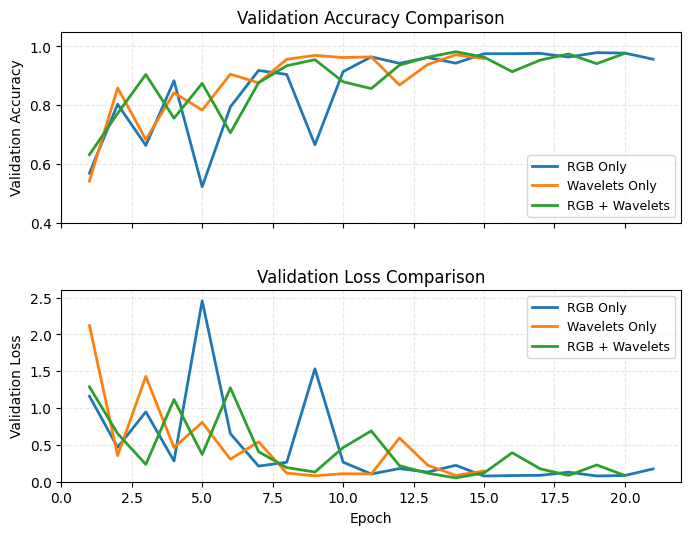

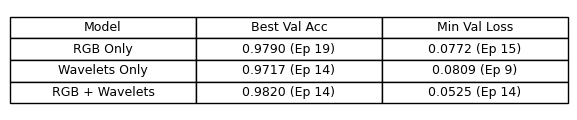

In [ ]:
# Validation accuracy and loss per epoch, copied from the training logs above.
# --- RGB Only ---
epochs_rgb = np.arange(1, 22)
val_acc_rgb = [0.5698,0.8039,0.6641,0.8837,0.5240,0.7947,0.9186,0.9050,0.6664,0.9146,
               0.9646,0.9427,0.9625,0.9432,0.9753,0.9754,0.9765,0.9640,0.9790,0.9774,0.9567]
val_loss_rgb = [1.1607,0.4665,0.9485,0.2816,2.4571,0.6526,0.2125,0.2639,1.5332,0.2655,
                0.1048,0.1786,0.1306,0.2229,0.0772,0.0837,0.0870,0.1292,0.0780,0.0847,0.1740]

# --- Wavelet Only ---
epochs_wav = np.arange(1, 16)
val_acc_wav = [0.5433,0.8595,0.6839,0.8429,0.7840,0.9059,0.8766,0.9564,0.9697,0.9624,
               0.9645,0.8691,0.9387,0.9717,0.9588]
val_loss_wav = [2.1196,0.3544,1.4302,0.4641,0.8053,0.3061,0.5417,0.1168,0.0809,0.1084,
                0.1058,0.5942,0.2248,0.0847,0.1456]

# --- RGB + Wavelet ---
epochs_fuse = np.arange(1, 21)
val_acc_fuse = [0.6327,0.7728,0.9048,0.7564,0.8747,0.7071,0.8768,0.9346,0.9551,0.8801,
                0.8569,0.9366,0.9635,0.9820,0.9639,0.9143,0.9539,0.9743,0.9416,0.9767]
val_loss_fuse = [1.2879,0.6531,0.2352,1.1157,0.3708,1.2748,0.4079,0.1918,0.1312,0.4632,
                 0.6902,0.2180,0.1148,0.0525,0.1183,0.3935,0.1743,0.0861,0.2276,0.0840]

# --- Stats for table ---
def get_summary(name, epochs, acc, loss):
    best_acc_idx = np.argmax(acc)
    best_loss_idx = np.argmin(loss)
    return [
        name,
        f"{acc[best_acc_idx]:.4f} (Ep {epochs[best_acc_idx]})",
        f"{loss[best_loss_idx]:.4f} (Ep {epochs[best_loss_idx]})"
    ]

summary_data = [
    get_summary("RGB Only", epochs_rgb, val_acc_rgb, val_loss_rgb),
    get_summary("Wavelets Only", epochs_wav, val_acc_wav, val_loss_wav),
    get_summary("RGB + Wavelets", epochs_fuse, val_acc_fuse, val_loss_fuse)
]

colors = {"RGB Only":"#1f77b4", "Wavelets Only":"#ff7f0e", "RGB + Wavelets":"#2ca02c"}

fig, axes = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
plt.subplots_adjust(hspace=0.35, bottom=0.15, top=0.9)

# Validation Accuracy
axes[0].plot(epochs_rgb, val_acc_rgb, label="RGB Only", color=colors["RGB Only"], linewidth=2)
axes[0].plot(epochs_wav, val_acc_wav, label="Wavelets Only", color=colors["Wavelets Only"], linewidth=2)
axes[0].plot(epochs_fuse, val_acc_fuse, label="RGB + Wavelets", color=colors["RGB + Wavelets"], linewidth=2)
axes[0].set_ylabel("Validation Accuracy")
axes[0].set_ylim(0.4, 1.05)
axes[0].grid(True, linestyle="--", alpha=0.3)
axes[0].legend(loc="lower right", fontsize=9)
axes[0].set_title("Validation Accuracy Comparison")

# Validation Loss
axes[1].plot(epochs_rgb, val_loss_rgb, label="RGB Only", color=colors["RGB Only"], linewidth=2)
axes[1].plot(epochs_wav, val_loss_wav, label="Wavelets Only", color=colors["Wavelets Only"], linewidth=2)
axes[1].plot(epochs_fuse, val_loss_fuse, label="RGB + Wavelets", color=colors["RGB + Wavelets"], linewidth=2)
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Validation Loss")
axes[1].set_ylim(0, 2.6)
axes[1].grid(True, linestyle="--", alpha=0.3)
axes[1].legend(loc="upper right", fontsize=9)
axes[1].set_title("Validation Loss Comparison")

# --- Summary table ---
fig_table, ax_table = plt.subplots(figsize=(6, 1.3))
ax_table.axis("off")

col_labels = ["Model", "Best Val Acc", "Min Val Loss"]
the_table = ax_table.table(
    cellText=summary_data,
    colLabels=col_labels,
    loc='center',
    cellLoc='center'
)
the_table.auto_set_font_size(False)
the_table.set_fontsize(9)
the_table.scale(1.2, 1.3)

plt.show()

In [ ]:
# Define the evaluation configuration: Model, Name, and its corresponding Dataset
eval_configurations = {
    "RGB Only": (model_rgb, test_ds_rgb),
    "Wavelets Only": (model_wavelets, test_ds_wavelet),
    "RGB + Wavelets": (model_rgb_wavelets, test_ds_rgb_wavelet)
}

# Extract true labels (Y_true) once. The labels are identical across all mapped test datasets.
Y_true = np.concatenate([y for x, y in test_ds_rgb], axis=0).astype(int).flatten()

# Evaluation and Comparison
results_df = pd.DataFrame()
all_preds = {}
roc_plots = {}
T = 0.5 # Classification threshold

for name, (model, dataset) in eval_configurations.items():

    # Predict probabilities using the correct dataset for the model
    Y_pred_proba = model.predict(dataset, verbose=0).flatten()

    # Store binary predictions
    Y_pred_binary = (Y_pred_proba > T).astype(int)
    all_preds[name] = Y_pred_binary

    # Calculate core metrics
    acc = metrics.accuracy_score(Y_true, Y_pred_binary)
    prec = metrics.precision_score(Y_true, Y_pred_binary)
    rec = metrics.recall_score(Y_true, Y_pred_binary)
    f1 = metrics.f1_score(Y_true, Y_pred_binary)

    # Calculate AUC-ROC
    fpr, tpr, thresholds = metrics.roc_curve(Y_true, Y_pred_proba)
    auc_score = metrics.auc(fpr, tpr)

    # Store results in DataFrame
    results_df = pd.concat([results_df, pd.DataFrame({
        'Model': name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1 Score': f1,
        'AUC-ROC': auc_score
    }, index=[0])], ignore_index=True)

    roc_plots[name] = (fpr, tpr, auc_score)

print("Evaluation complete.")

Evaluation complete.

### Test set metrics

In [ ]:
# Performance Metrics Comparison
pd.set_option('display.float_format', lambda x: '%.4f' % x)
display(results_df.sort_values(by='AUC-ROC', ascending=False))

,Model,Accuracy,Precision,Recall,F1 Score,AUC-ROC
2,RGB + Wavelets,0.9812,0.9847,0.9776,0.9811,0.9986
1,Wavelets Only,0.9707,0.9853,0.9557,0.9703,0.9972
0,RGB Only,0.9769,0.9787,0.9750,0.9769,0.9971


### ROC curves

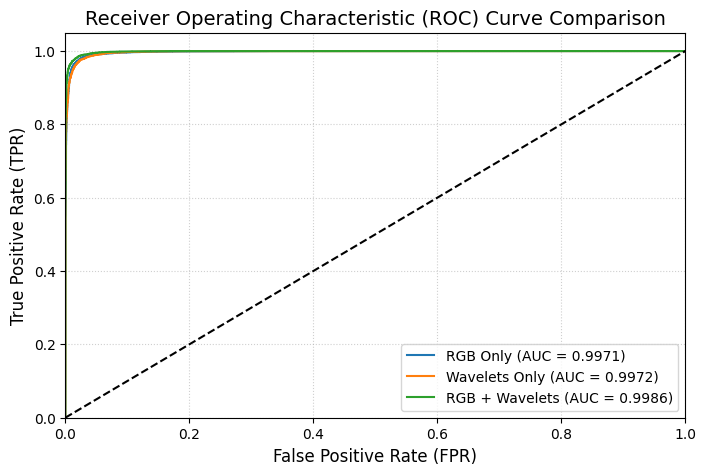

In [ ]:
# Plot ROC Curve
plt.figure(figsize=(8, 5))
for name, (fpr, tpr, auc_score) in roc_plots.items():
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc_score:.4f})')

plt.plot([0, 1], [0, 1], 'k--') # Diagonal line for random guess
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)', fontsize=12)
plt.ylabel('True Positive Rate (TPR)', fontsize=12)
plt.title('Receiver Operating Characteristic (ROC) Curve Comparison', fontsize=14)
plt.legend(loc="lower right")
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

### Confusion matrices

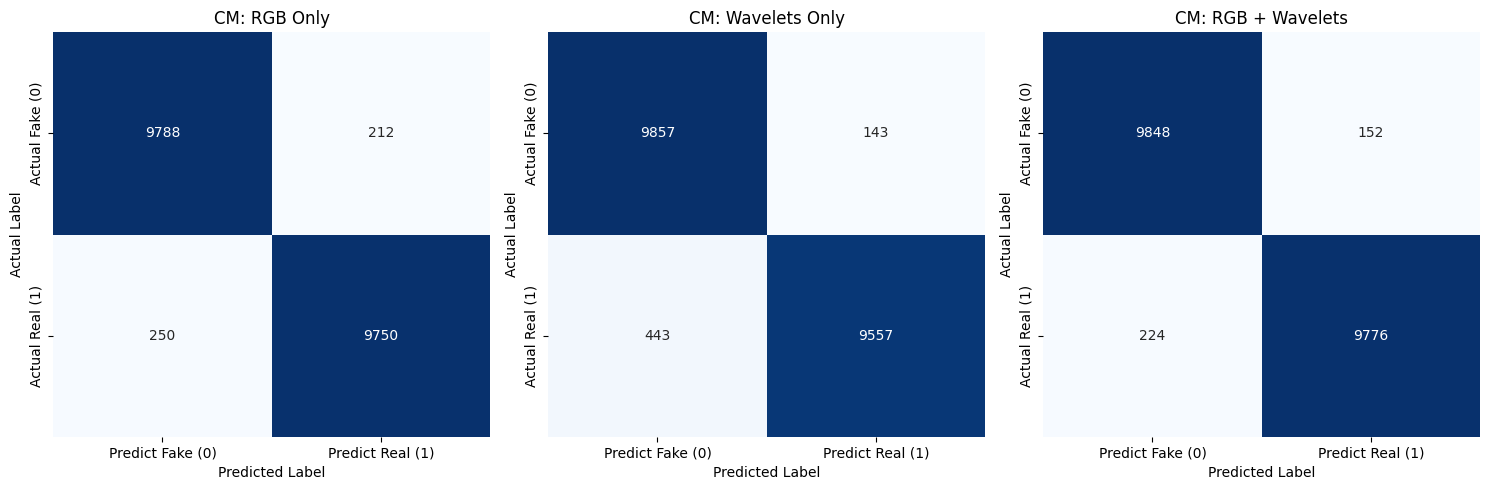

In [ ]:
# Plot Confusion Matrices
plt.figure(figsize=(15, 5))

for i, (name, Y_pred) in enumerate(all_preds.items()):
    conf_mat = metrics.confusion_matrix(Y_true, Y_pred)

    plt.subplot(1, len(eval_configurations), i + 1)
    sns.heatmap(conf_mat, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Predict Fake (0)', 'Predict Real (1)'],
                yticklabels=['Actual Fake (0)', 'Actual Real (1)'])
    plt.title(f'CM: {name}')
    plt.ylabel('Actual Label')
    plt.xlabel('Predicted Label')

plt.tight_layout()
plt.show()

### Variability across test subsets, bootstrap confidence intervals and McNemar's test

The fixed models are evaluated on 10 stratified, non-overlapping subsets of the test set
(2,000 images each) to report mean ± std. No model is retrained.
McNemar's test compares the RGB and the combined model on the same 20,000 test images.

In [ ]:
k = 10
threshold = 0.5
random_state = 42

def collect_labels(ds):
    ys = []
    for _, yb in ds:
        ys.append(np.asarray(yb))
    return np.concatenate(ys, axis=0).astype(int).flatten()

Y = collect_labels(test_ds_rgb)
n = len(Y)
print("labels:", n)

def predict_probs(model, ds):
    probs = model.predict(ds.prefetch(tf.data.AUTOTUNE), verbose=1)
    return np.asarray(probs).flatten()

evals = {
    "RGB Only": (model_rgb, test_ds_rgb),
    "Wavelets Only": (model_wavelets, test_ds_wavelet),
    "RGB + Wavelets": (model_rgb_wavelets, test_ds_rgb_wavelet)
}

skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=random_state)
results = []

for name, (model, ds) in evals.items():
    print(f"\nEvaluating: {name}")
    probs = predict_probs(model, ds)          # streaming predict, memory-friendly
    if probs.shape[0] != n:
        raise ValueError(f"{name}: probs length {probs.shape[0]} != labels length {n}")

    fold_metrics = []
    for _, test_idx in skf.split(np.zeros(n), Y):
        y_true = Y[test_idx]
        y_proba = probs[test_idx]
        y_pred = (y_proba > threshold).astype(int)

        acc = metrics.accuracy_score(y_true, y_pred)
        prec = metrics.precision_score(y_true, y_pred, zero_division=0)
        rec = metrics.recall_score(y_true, y_pred, zero_division=0)
        f1 = metrics.f1_score(y_true, y_pred, zero_division=0)
        fpr, tpr, _ = metrics.roc_curve(y_true, y_proba)
        auc = metrics.auc(fpr, tpr)

        fold_metrics.append([acc, prec, rec, f1, auc])

    fold_metrics = np.array(fold_metrics)
    results.append([
        name,
        fold_metrics[:,0].mean(), fold_metrics[:,0].std(),
        fold_metrics[:,1].mean(), fold_metrics[:,1].std(),
        fold_metrics[:,2].mean(), fold_metrics[:,2].std(),
        fold_metrics[:,3].mean(), fold_metrics[:,3].std(),
        fold_metrics[:,4].mean(), fold_metrics[:,4].std(),
    ])

cols = ["Model",
        "Acc_mean","Acc_std","Prec_mean","Prec_std",
        "Rec_mean","Rec_std","F1_mean","F1_std","AUC_mean","AUC_std"]
results_df = pd.DataFrame(results, columns=cols)
print("\nFinal results:")
print(results_df)

labels: 20000

Evaluating: RGB Only
157/157 ━━━━━━━━━━━━━━━━━━━━ 31s 192ms/step

Evaluating: Wavelets Only
157/157 ━━━━━━━━━━━━━━━━━━━━ 92s 552ms/step

Evaluating: RGB + Wavelets
157/157 ━━━━━━━━━━━━━━━━━━━━ 99s 596ms/step

Final results:
            Model  Acc_mean   Acc_std  Prec_mean  Prec_std  Rec_mean  \
0        RGB Only   0.97690  0.003345   0.978742  0.004982    0.9750   
1   Wavelets Only   0.97065  0.004433   0.985258  0.004365    0.9556   
2  RGB + Wavelets   0.98115  0.002157   0.984610  0.003680    0.9776   

    Rec_std   F1_mean    F1_std  AUC_mean   AUC_std  
0  0.003924  0.976858  0.003333  0.997097  0.000839  
1  0.005238  0.970199  0.004519  0.997148  0.000750  
2  0.003955  0.981082  0.002167  0.998595  0.000475  

In [ ]:
# Define evaluation configurations for each model and dataset
eval_configurations = {
    "RGB Only": (model_rgb, test_ds_rgb),
    "Wavelets Only": (model_wavelets, test_ds_wavelet),
    "RGB + Wavelets": (model_rgb_wavelets, test_ds_rgb_wavelet)
}

N_BOOT = 1000
TH = 0.5

probs = {}
preds_bin = {}
Y_true = None

for name, (model, dataset) in eval_configurations.items():
    probs[name] = model.predict(dataset, verbose=0).flatten()
    preds_bin[name] = (probs[name] > TH).astype(int)
    if Y_true is None:
        Y_true = np.concatenate([y for x, y in dataset], axis=0).astype(int).flatten()

rows = []
for name in probs:
    p = preds_bin[name]
    rows.append({
        "Model": name,
        "Accuracy": metrics.accuracy_score(Y_true, p),
        "Precision": metrics.precision_score(Y_true, p, zero_division=0),
        "Recall": metrics.recall_score(Y_true, p, zero_division=0),
        "F1": metrics.f1_score(Y_true, p, zero_division=0),
        "AUC": metrics.roc_auc_score(Y_true, probs[name])
    })
global_df = pd.DataFrame(rows)

def bootstrap_ci(y_true, y_proba, stat_fn, n_boot=N_BOOT):
    n = len(y_true)
    vals = []
    for _ in range(n_boot):
        idx = np.random.choice(n, n, replace=True)
        yt = y_true[idx]
        yp = y_proba[idx]
        vals.append(stat_fn(yt, yp))
    lo, hi = np.percentile(vals, [2.5, 97.5])
    return np.mean(vals), lo, hi

def stat_accuracy(yt, yp):
    return metrics.accuracy_score(yt, (yp>TH).astype(int))
def stat_precision(yt, yp):
    return metrics.precision_score(yt, (yp>TH).astype(int), zero_division=0)
def stat_recall(yt, yp):
    return metrics.recall_score(yt, (yp>TH).astype(int), zero_division=0)
def stat_f1(yt, yp):
    return metrics.f1_score(yt, (yp>TH).astype(int), zero_division=0)
def stat_auc(yt, yp):
    return metrics.roc_auc_score(yt, yp)

ci_rows = []
for name in probs:
    mean_acc, lo_acc, hi_acc = bootstrap_ci(Y_true, probs[name], stat_accuracy)
    mean_pre, lo_pre, hi_pre = bootstrap_ci(Y_true, probs[name], stat_precision)
    mean_rec, lo_rec, hi_rec = bootstrap_ci(Y_true, probs[name], stat_recall)
    mean_f1, lo_f1, hi_f1 = bootstrap_ci(Y_true, probs[name], stat_f1)
    mean_auc, lo_auc, hi_auc = bootstrap_ci(Y_true, probs[name], stat_auc)
    ci_rows.append({
        "Model": name,
        "Acc_mean": mean_acc, "Acc_95ci": f"{lo_acc:.4f}-{hi_acc:.4f}",
        "Prec_mean": mean_pre, "Prec_95ci": f"{lo_pre:.4f}-{hi_pre:.4f}",
        "Rec_mean": mean_rec, "Rec_95ci": f"{lo_rec:.4f}-{hi_rec:.4f}",
        "F1_mean": mean_f1, "F1_95ci": f"{lo_f1:.4f}-{hi_f1:.4f}",
        "AUC_mean": mean_auc, "AUC_95ci": f"{lo_auc:.4f}-{hi_auc:.4f}"
    })

ci_df = pd.DataFrame(ci_rows)

# McNemar test: RGB Only vs RGB + Wavelets
a = preds_bin["RGB Only"]
b = preds_bin["RGB + Wavelets"]

b00 = np.sum((a==Y_true) & (b==Y_true))  # both correct
b01 = np.sum((a==Y_true) & (b!=Y_true))  # a correct, b wrong
b10 = np.sum((a!=Y_true) & (b==Y_true))  # a wrong, b correct
b11 = np.sum((a!=Y_true) & (b!=Y_true))  # both wrong
table = [[b00, b01],[b10,b11]]
mcnemar_res = mcnemar(table, exact=False, correction=True)

print("Global metrics:\n", global_df)
print("\nBootstrap CIs:\n", ci_df)
print("\nMcNemar (RGB Only vs RGB+Wavelets):")
print(" contingency table:", table)
print(" statistic=%.4f p=%.6f" % (mcnemar_res.statistic, mcnemar_res.pvalue))

Global metrics:
             Model  Accuracy  Precision  Recall        F1       AUC
0        RGB Only    0.9769   0.978719  0.9750  0.976856  0.997123
1   Wavelets Only    0.9707   0.985258  0.9557  0.970254  0.997172
2  RGB + Wavelets    0.9812   0.984690  0.9776  0.981132  0.998575

Bootstrap CIs:
             Model  Acc_mean       Acc_95ci  Prec_mean      Prec_95ci  \
0        RGB Only  0.976902  0.9748-0.9791   0.978790  0.9760-0.9817   
1   Wavelets Only  0.970736  0.9683-0.9732   0.985252  0.9829-0.9878   
2  RGB + Wavelets  0.981191  0.9794-0.9830   0.984707  0.9822-0.9869   

   Rec_mean       Rec_95ci   F1_mean        F1_95ci  AUC_mean       AUC_95ci  
0  0.975066  0.9719-0.9781  0.976837  0.9747-0.9789  0.997116  0.9967-0.9976  
1  0.955783  0.9517-0.9595  0.970225  0.9677-0.9728  0.997171  0.9967-0.9976  
2  0.977581  0.9746-0.9804  0.981107  0.9791-0.9831  0.998571  0.9983-0.9988  

McNemar (RGB Only vs RGB+Wavelets):
 contingency table: [[np.int64(19209), np.int64(329)], [

## 5. Grad-CAM

In [ ]:
LAST_CONV_LAYER_NAME = "conv5_block16_concat"
models = {"RGB Only": model_rgb, "Wavelets Only": model_wavelets, "RGB + Wavelets": model_rgb_wavelets}


def get_processed_array(img_path: str, model_name: str, size: tuple):
    """Loads one image and applies the validation preprocessing of the given model."""
    img = keras.utils.load_img(img_path, target_size=size)
    array = keras.utils.img_to_array(img)
    raw_tensor = tf.constant(array[np.newaxis, ...], dtype=tf.uint8)

    if model_name == "Wavelets Only":
        processed_array, _ = preprocess_wavelet_only_valid(raw_tensor, tf.constant([0]))
    elif model_name == "RGB + Wavelets":
        processed_array, _ = preprocess_rgb_wavelet_valid(raw_tensor, tf.constant([0]))
    else:
        processed_array, _ = preprocess_rgb_only_valid(raw_tensor, tf.constant([0]))
    return processed_array


def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    """Grad-CAM heatmap for the predicted (or given) class of a sigmoid model."""
    grad_model = keras.models.Model(
        model.inputs,
        [model.get_layer(last_conv_layer_name).output, model.output]
    )

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        if pred_index is None:
            pred_index = int(tf.round(predictions[0, 0]))
        # Sigmoid output: the score for class 1 is p, for class 0 it is 1 - p
        class_channel = predictions[:, 0] if pred_index == 1 else 1.0 - predictions[:, 0]

    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    heatmap = conv_outputs[0] @ tf.cast(pooled_grads, conv_outputs.dtype)[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    return tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-7)


def overlay(orig, heat, alpha=0.5):
    h = np.uint8(255 * np.clip(heat, 0, 1))
    cmap = np.uint8(plt.get_cmap("jet")(np.arange(256))[:, :3] * 255)[h]
    cmap = np.array(Image.fromarray(cmap).resize((orig.shape[1], orig.shape[0]), Image.BILINEAR))
    return np.clip(cmap * alpha + orig * (1 - alpha), 0, 255).astype(np.uint8)


def get_cm_name(y_true, pc):
    """Confusion-matrix cell of one prediction (class 1 = real)."""
    return {(1, 1): "TP", (0, 1): "FP", (0, 0): "TN", (1, 0): "FN"}[(int(y_true), int(pc))]

In [ ]:
ds_map = {"RGB Only": test_ds_rgb, "Wavelets Only": test_ds_wavelet, "RGB + Wavelets": test_ds_rgb_wavelet}

predictions = {}
for name, model in models.items():
    print(f"Predicting for {name}...")
    pv_all = model.predict(ds_map[name], verbose=0).ravel()
    predictions[name] = {"pv": pv_all, "pc": (pv_all >= 0.5).astype(int)}

Predicting for RGB Only...
Predicting for Wavelets Only...
Predicting for RGB + Wavelets...

In [ ]:
MODEL_R, MODEL_W, MODEL_RW = "RGB Only", "Wavelets Only", "RGB + Wavelets"
MAX_SAMPLES = 10

# Test image paths in the same order as test_ds (sorted class folders, sorted files)
test_dir = os.path.join(dataset_dir, "test")
paths, labels = [], []
for cls_idx, d in enumerate(sorted(os.listdir(test_dir))):
    folder = os.path.join(test_dir, d)
    for f in sorted(os.listdir(folder)):
        if f.lower().endswith((".jpg", ".jpeg", ".png")):
            paths.append(os.path.join(folder, f))
            labels.append(cls_idx)
paths = np.array(paths)
y_true = np.array(labels)

pc_R = predictions[MODEL_R]["pc"]
pc_W = predictions[MODEL_W]["pc"]
pc_RW = predictions[MODEL_RW]["pc"]


def select_samples(y_true, pc_A, pc_B, pred_A_correct, pred_B_correct, max_count):
    condition = ((pc_A == y_true) == pred_A_correct) & ((pc_B == y_true) == pred_B_correct)
    indices = np.where(condition)[0]
    if len(indices) > max_count:
        return random.sample(list(indices), max_count)
    return list(indices)


# Figure A: RGB Only vs. Wavelets Only
chosen_A = {
    "W_Corrects_R": select_samples(y_true, pc_R, pc_W, False, True, MAX_SAMPLES),
    "R_Corrects_W": select_samples(y_true, pc_R, pc_W, True, False, MAX_SAMPLES),
    "Common_Failure": select_samples(y_true, pc_R, pc_W, False, False, MAX_SAMPLES),
}

# Figure B: RGB Only vs. RGB + Wavelets
chosen_B = {
    "Fusion_Improved": select_samples(y_true, pc_R, pc_RW, False, True, MAX_SAMPLES),
    "Fusion_Degraded": select_samples(y_true, pc_R, pc_RW, True, False, MAX_SAMPLES),
    "Common_Success": select_samples(y_true, pc_R, pc_RW, True, True, MAX_SAMPLES),
}


def precompute_gradcam(indices):
    """Original image, prediction and Grad-CAM heatmap of every model for the chosen samples."""
    start_time = time.time()
    precomputed = {}
    for idx in indices:
        p = paths[idx]
        orig_img = keras.utils.img_to_array(keras.utils.load_img(p, target_size=IMG_SIZE)).astype(np.uint8)
        gc_results = {}
        for name, m in models.items():
            arr = get_processed_array(p, name, IMG_SIZE)
            pv = predictions[name]["pv"][idx]
            pc = predictions[name]["pc"][idx]
            heat = make_gradcam_heatmap(arr, m, LAST_CONV_LAYER_NAME, pred_index=pc).numpy()
            gc_results[name] = {"pv": pv, "pc": pc, "cm_name": get_cm_name(y_true[idx], pc), "heatmap": heat}
        precomputed[idx] = {"orig": orig_img, "y_true": y_true[idx], "gc_data": gc_results}
    print(f"Grad-CAM pre-computation finished in {time.time() - start_time:.2f} seconds.")
    return precomputed


def generate_figure(chosen_dict, precomputed, models_to_plot, title):
    rows = [(group, precomputed[idx]) for group, indices in chosen_dict.items()
            for idx in indices if idx in precomputed]
    if not rows:
        print(f"Warning: no samples found for {title}.")
        return

    n_cols = 1 + len(models_to_plot)
    fig, axes = plt.subplots(len(rows), n_cols, figsize=(4 * n_cols, 3 * len(rows)), squeeze=False)
    for r, (group, data) in enumerate(rows):
        axes[r, 0].imshow(data["orig"])
        axes[r, 0].set_title(f"{group}\nTrue={data['y_true']}", fontsize=8)
        axes[r, 0].axis("off")
        for c, name in enumerate(models_to_plot, start=1):
            g = data["gc_data"][name]
            axes[r, c].imshow(overlay(data["orig"], g["heatmap"]))
            axes[r, c].set_title(f"{name}\n{g['cm_name']} Pred={g['pv']:.3f} C={g['pc']}", fontsize=8)
            axes[r, c].axis("off")
    fig.suptitle(title, fontsize=14)
    plt.tight_layout(rect=[0, 0.03, 1, 0.98])
    plt.show()


all_indices = set()
for chosen in (chosen_A, chosen_B):
    for indices in chosen.values():
        all_indices.update(indices)
precomputed_results = precompute_gradcam(list(all_indices))

generate_figure(chosen_A, precomputed_results, [MODEL_R, MODEL_W],
                "Figure A: Independent Feature Comparison (RGB Only vs. Wavelets Only)")
generate_figure(chosen_B, precomputed_results, [MODEL_R, MODEL_RW],
                "Figure B: Feature Fusion Effect (RGB Only vs. RGB + Wavelets)")

In [ ]:
def select_triple_samples(correct_R, correct_W, correct_RW, max_count=MAX_SAMPLES):
    """Samples by the correctness of all three models."""
    condition = (((pc_R == y_true) == correct_R)
                 & ((pc_W == y_true) == correct_W)
                 & ((pc_RW == y_true) == correct_RW))
    indices = np.where(condition)[0]
    if len(indices) > max_count:
        return random.sample(list(indices), max_count)
    return list(indices)


chosen_comparison = {
    "Fusion_Win": select_triple_samples(False, False, True),          # only the combined model is right
    "Wavelets_Only_Win": select_triple_samples(False, True, False),   # only the wavelet model is right
    "Common_Failure": select_triple_samples(False, False, False),     # all three are wrong
}

triple_indices = set()
for indices in chosen_comparison.values():
    triple_indices.update(indices)
print(f"{len(triple_indices)} unique samples chosen for the three-model comparison.")

precomputed_triple = precompute_gradcam(list(triple_indices))
generate_figure(chosen_comparison, precomputed_triple, [MODEL_R, MODEL_W, MODEL_RW],
                "Figure C: Three-Model Comparison (Fusion Success, Degradation, and Failure)")

In [ ]:
# One random TP, FP, TN and FN example (judged by the RGB model) with the heatmaps of all models
GRADCAM_SEED = 9
random.seed(GRADCAM_SEED)
REF = "RGB Only"

chosen = {}
while len(chosen) < 4:
    idx = random.randint(0, len(paths) - 1)
    chosen.setdefault(get_cm_name(y_true[idx], predictions[REF]["pc"][idx]), idx)

rows = ["TP", "FP", "TN", "FN"]
fig, axes = plt.subplots(4, 1 + len(models), figsize=(4 * (1 + len(models)), 16))
for r, key in enumerate(rows):
    idx = chosen[key]
    orig = keras.utils.img_to_array(keras.utils.load_img(paths[idx], target_size=IMG_SIZE)).astype(np.uint8)
    axes[r, 0].imshow(orig)
    axes[r, 0].set_title(f"{key}\nTrue={y_true[idx]}")
    axes[r, 0].axis("off")
    for c, (name, m) in enumerate(models.items(), start=1):
        arr = get_processed_array(paths[idx], name, IMG_SIZE)
        pv = float(predictions[name]["pv"][idx])
        pc = int(pv >= 0.5)
        heat = make_gradcam_heatmap(arr, m, LAST_CONV_LAYER_NAME, pred_index=pc).numpy()
        axes[r, c].imshow(overlay(orig, heat))
        axes[r, c].set_title(f"{name}\nPred={pv:.3f} C={pc}")
        axes[r, c].axis("off")
plt.tight_layout()
plt.show()

Output hidden; open in https://colab.research.google.com to view.